# J6 · The limb integral in Bartky's variable

**Level:** advanced · **Prerequisites:** [J1](J1_quickstart.ipynb), [J3](J3_precision_and_rigour.ipynb)
· **Run time:** ~2 min (mostly compilation)

**Covers:** Sect. 6.4 of the paper step by step, each claim checked numerically: the limb
integral as a complete integral in the rim angle $\vartheta$; Bartky's variable $\beta$ with
$\tan\vartheta = \sinh\beta$; why the trapezoid rule on fixed nodes converges geometrically and
uniformly up to both contacts (a strip of analyticity of fixed width, plus a pole removed by
its residue); the shifted contour inside the disk; the connection formula
$\mathcal K = \mathcal K_{\rm reg} + y^\nu \mathcal K_{\rm sing}$ that makes Chebyshev
interpolants possible; a generic implementation that gives `BigFloat` references for free;
and the cost of the package's optimised rules.

In [1]:
using Pizzetti, QuadGK, BenchmarkTools, Plots
include("theme.jl")

## 1. From the rim integral to a complete integral

On the limb ($1 - p < z < 1 + p$), Green's theorem reduces the blocked integral
$P_\alpha = \int \mu^\alpha\,\mathrm{d}A$ over the occulted area to a line integral along the
occulter's rim inside the star (paper, Eq. 8, with $s = r^2$). With $x = 1 - (z - p)^2$,
$k = x / (4zp)$, $y = 1 - k$ and the rim angle $\vartheta$ defined by
$1 - s = x\cos^2\vartheta$, it becomes a complete integral of Legendre type (Eq. 43),

$$P_\alpha = -\frac{2\sqrt{k}\,x^{\alpha/2+1}}{\alpha+2}\,\mathcal K(y; x),\qquad
\mathcal K(y; x) = \int_0^{\pi/2} \frac{\cos^{\alpha+3}\vartheta}{\sqrt{1 - k\sin^2\vartheta}}
\left[1 + \frac{p^2 - z^2}{1 - x\cos^2\vartheta}\right]\mathrm{d}\vartheta,$$

and Bartky's substitution $\tan\vartheta = \sinh\beta$ maps it onto the half line,

$$\mathcal K(y; x) = \int_0^\infty \frac{\cosh^{-(\alpha+3)}\beta}{\sqrt{1 + y\sinh^2\beta}}
\left[1 + \frac{(p^2 - z^2)\cosh^2\beta}{\cosh^2\beta - x}\right]\mathrm{d}\beta.$$

We write $\mathcal K(u; w)$ as a function of two arguments; along the light curve $u = y$ and
$w = x$.

In [2]:
geom(z, p) = (x = 1 - (z - p)^2; k = x / (4z * p); (x = x, k = k, y = 1 - k, c0 = p^2 - z^2))
prefactor(g, α) = -2sqrt(g.k) * g.x^(α / 2 + 1) / (α + 2)

"𝒦 in the rim angle ϑ, by adaptive quadrature (the textbook form)."
K_theta(k, x, c0, α; rtol = 1e-14) =
    quadgk(ϑ -> cos(ϑ)^(α + 3) / sqrt(1 - k * sin(ϑ)^2) * (1 + c0 / (1 - x * cos(ϑ)^2)), 0, π / 2; rtol = rtol)[1];

The trapezoid rule in $\beta$, written generically: it runs in any number type `T`. The
integrand has simple poles where $\cosh^2\beta = w$, at $\beta = \pm i\arccos\sqrt{w}$; their
contribution to the trapezoid error is a geometric series of residues, known in closed form
and subtracted (`pole = true`).

In [3]:
function K_bartky(u, w, c0, α; h = 0.2, tail = 1e-16, pole = true)
    T = float(promote_type(typeof(u), typeof(w), typeof(c0), typeof(h)))
    f(β) = cosh(β)^(-(α + 3)) / sqrt(1 + u * sinh(β)^2) * (1 + c0 * cosh(β)^2 / (cosh(β)^2 - w))
    N = ceil(Int, (log(1 / T(tail)) + (α + 3) * log(T(2))) / ((α + 3) * h)) + 1   # cosh^-(α+3) < tail
    s = f(zero(T)) / 2
    for n in 1:N
        s += f(n * h)
    end
    s *= h
    d = 1 - u * (1 - w)
    if pole && 0 < w < 1 && d > 0
        a = acos(sqrt(w))
        e = exp(-2T(π) * a / h)
        s -= T(π) * c0 * sqrt(w) / sqrt((1 - w) * d) * e / (1 - e) * w^(-(α + 3) / 2)
    end
    return s
end;

The three routes to $P_\alpha$ agree across the limb, from just outside second contact to just
inside first contact ($p = 0.1$, $\alpha = 0.6$):

In [4]:
p, α = 0.1, 0.6
fmt15(v) = @sprintf("%.15e", v)
table(["z", "rim angle ϑ (quadgk)", "Bartky trapezoid, h = 0.2", "Green's-theorem quadrature"],
      [(@sprintf("%.10g", z), fmt15(prefactor(geom(z, p), α) * K_theta(geom(z, p).k, geom(z, p).x, geom(z, p).c0, α)),
        fmt15(prefactor(geom(z, p), α) * K_bartky(geom(z, p).y, geom(z, p).x, geom(z, p).c0, α)),
        fmt15(blocked_flux(z, p, α / 2; limb = :quadrature))) for z in (0.9 + 1e-9, 0.95, 1.0, 1.05, 1.1 - 1e-9)])

z,rim angle ϑ (quadgk),"Bartky trapezoid, h = 0.2",Green's-theorem quadrature
0.900000001,1.829160415884479e-02,1.829160415884480e-02,1.829160415884495e-02
0.95,1.278030363272274e-02,1.278030363272275e-02,1.278030363272269e-02
1,6.834436331858481e-03,6.834436331858483e-03,6.834436331858392e-03
1.05,2.125028113885403e-03,2.125028113885401e-03,2.125028113885337e-03
1.099999999,3.142835672125245e-17,3.142746085528917e-17,0.000000000000000e+00


## 2. Why a trapezoid rule with fixed nodes works: a strip of fixed width

The trapezoid rule on $\beta_n = nh$ converges like $\exp(-2\pi d/h)$ for an integrand that is
analytic in the strip $|\mathrm{Im}\,\beta| < d$. The branch points of
$(1 + y\sinh^2\beta)^{-1/2}$ lie where $\sinh^2\beta = -1/y$; for $0 < y < 1$ this is on the
line $\mathrm{Im}\,\beta = \pi/2$, for *every* modulus. The factor $\cosh^{-(\alpha+3)}\beta$ is
singular on the same line. So $d = \pi/2$ all the way to both contacts, and the rule converges
like $\exp(-\pi^2/h)$, uniformly in $z$. Only the two simple poles $\cosh^2\beta = x$ lie closer
to the real axis, and their effect is removed exactly by the residue term.

The modulus of the integrand in the complex $\beta$ plane, mid-limb and just inside second
contact:

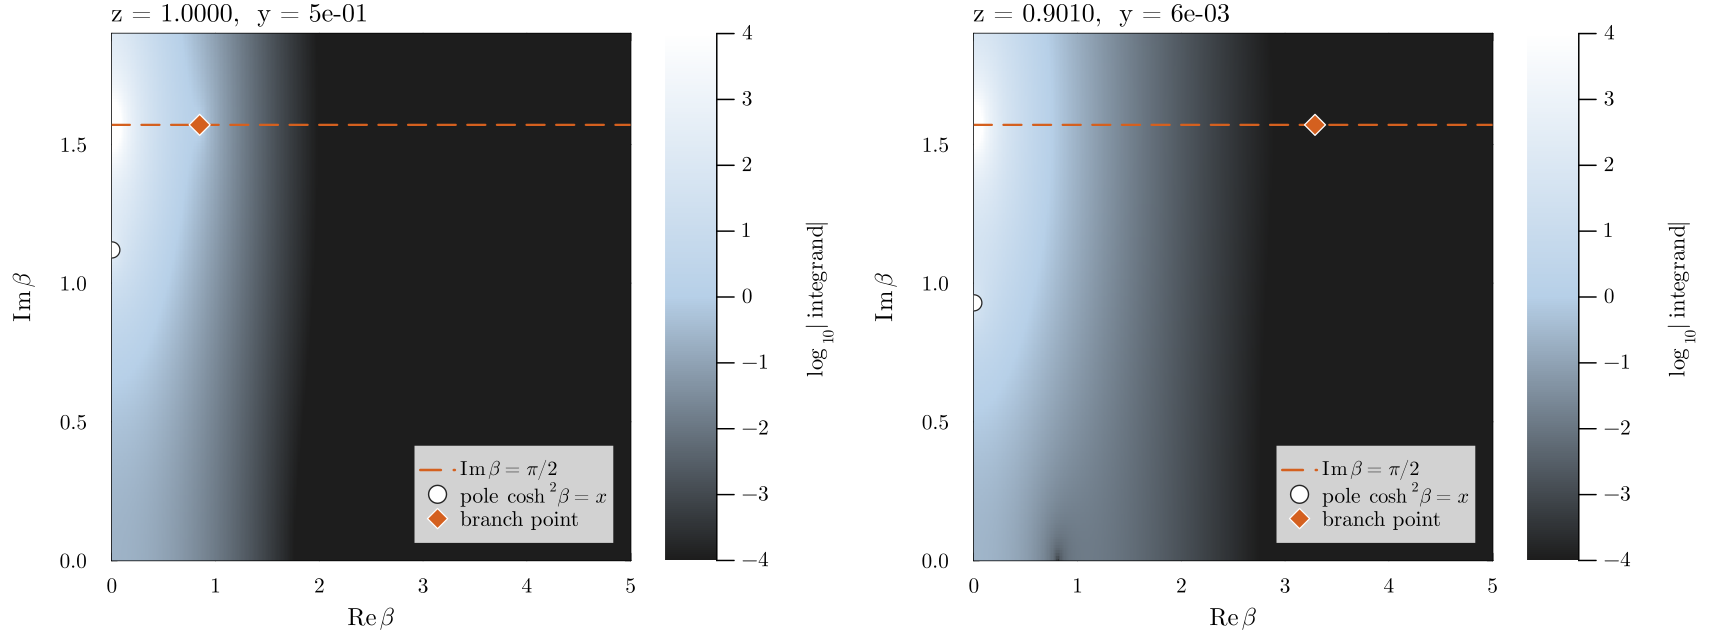

In [5]:
function integrand_map(z, p, α)
    g = geom(z, p)
    f(β) = cosh(β)^(-(α + 3)) / sqrt(1 + g.y * sinh(β)^2) * (1 + g.c0 * cosh(β)^2 / (cosh(β)^2 - g.x))
    re = range(0, 5, length = 401)
    im_ = range(0, 1.9, length = 191)
    L = [log10(abs(f(complex(r, i))) + 1e-300) for i in im_, r in re]
    plt = heatmap(re, im_, clamp.(L, -4, 4); c = cgrad([colorant"#1d1d1d", FILLS.series, :white]), clims = (-4, 4), xlims = (0, 5), ylims = (0, 1.9),
                  xlabel = L"\mathrm{Re}\,\beta", ylabel = L"\mathrm{Im}\,\beta", colorbar_title = L"\log_{10}|\mathrm{integrand}|",
                  title = @sprintf("z = %.4f,  y = %.0e", z, g.y), titlelocation = :left, legend = :bottomright)
    hline!(plt, [π / 2], color = COLORS.limb, ls = :dash, lw = 1.5, label = L"\mathrm{Im}\,\beta = \pi/2")
    scatter!(plt, [0.0], [acos(sqrt(g.x))], color = :white, msc = COLORS.ink, ms = 6, label = L"pole $\cosh^2\beta = x$")
    scatter!(plt, [acosh(1 / sqrt(g.y))], [π / 2], color = COLORS.limb, msc = :white, marker = :diamond, ms = 7,
             label = "branch point")
end
plt = plot(integrand_map(1.0, p, α), integrand_map(0.9 + 1e-3, p, α), layout = (1, 2), size = (1150, 430),
           left_margin = 6Plots.mm, bottom_margin = 6Plots.mm, right_margin = 4Plots.mm)
plt

On $\mathrm{Im}\,\beta = \pi/2$, $\sinh^2\beta = -\cosh^2(\mathrm{Re}\,\beta)$, so the branch point
sits at $\mathrm{Re}\,\beta = \mathrm{arccosh}(1/\sqrt{y})$: it moves outwards as $y \to 0$, but
never leaves the line.

Convergence against the step $h$, with a `BigFloat` reference from the same generic code
($h = 0.1$ in 256-bit arithmetic, where the discretisation error $\exp(-\pi^2/h)$ is $10^{-43}$):

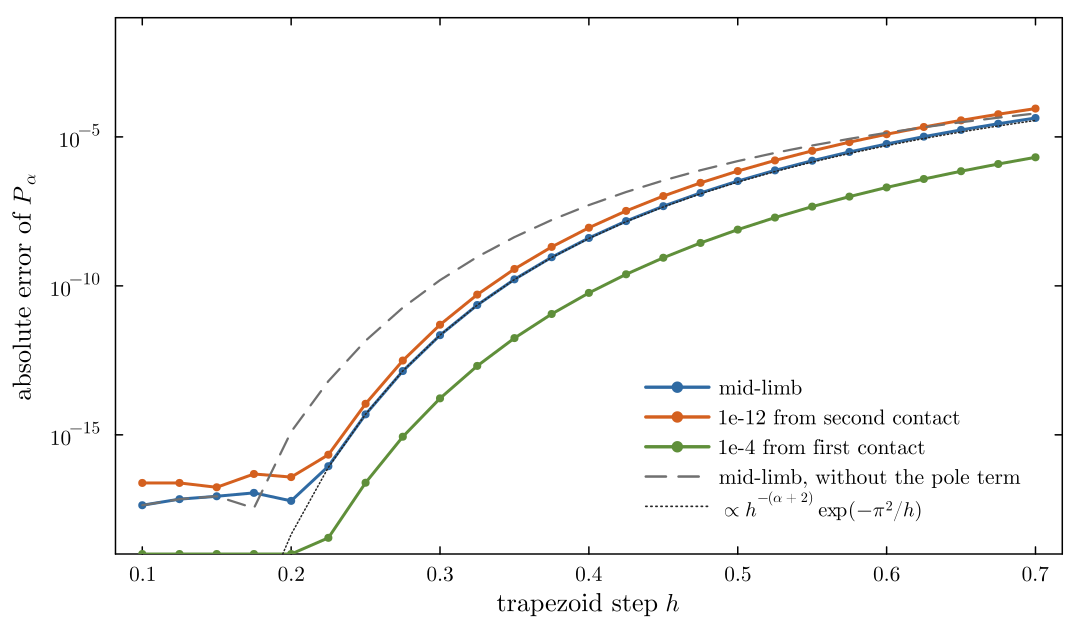

In [6]:
cases = (("mid-limb", 1.0), ("1e-12 from second contact", 0.9 + 1e-12), ("1e-4 from first contact", 1.1 - 1e-4))
ref = Dict(name => setprecision(BigFloat, 256) do
               g = geom(big(z), big(p))
               prefactor(g, big(α)) * K_bartky(g.y, g.x, g.c0, big(α); h = big"0.1", tail = 1e-45)
           end for (name, z) in cases)
Ph(z; kw...) = (g = geom(z, p); prefactor(g, α) * K_bartky(g.y, g.x, g.c0, α; kw...))
hs = 0.1:0.025:0.7
plt = plot(xlabel = L"trapezoid step $h$", ylabel = L"absolute error of $P_\alpha$", yscale = :log10,
           ylims = (1e-19, 1e-1), legend = :bottomright, size = (720, 420))
for (j, (name, z)) in enumerate(cases)
    r = Float64(ref[name])
    err = [max(abs(Ph(z; h = h) - r), 1e-19) for h in hs]
    plot!(plt, hs, err, lw = 2, color = (COLORS.series, COLORS.limb, COLORS.quadratic)[j], marker = :circle, ms = 3,
          msw = 0, label = name)
end
r = Float64(ref["mid-limb"])
plot!(plt, hs, [max(abs(Ph(1.0; h = h, pole = false) - r), 1e-19) for h in hs], lw = 1.5, color = COLORS.out,
      ls = :dash, label = "mid-limb, without the pole term")
model(h) = h^(-(α + 2)) * exp(-π^2 / h)
C0 = abs(Ph(1.0; h = 0.3) - r) / model(0.3)                 # scaled to the mid-limb error at h = 0.3
plot!(plt, hs, C0 .* model.(hs), color = COLORS.ink, lw = 1, ls = :dot, label = L"\propto h^{-(\alpha+2)}\exp(-\pi^2/h)")
plt

Without the pole term the error decays only like $\exp(-2\pi\arccos\sqrt{x}/h)$, set by the
poles. With it, all three cases decay like $\exp(-\pi^2/h)$ down to rounding, times an algebraic
factor $h^{-(\alpha+2)}$: the singularities of $\cosh^{-(\alpha+3)}\beta$ on
$\mathrm{Im}\,\beta = \pi/2$ are poles of order $\alpha + 3$, and a singularity of order $m$
contributes $(2\pi/h)^{m-1}\exp(-2\pi d/h)$ to the trapezoid error. At the package's step
$h = 0.2$:

In [7]:
table(["case", "P_α", "error at h = 0.2"],
      [(name, @sprintf("%.6e", Float64(ref[name])), sci(abs(Ph(z) - Float64(ref[name])))) for (name, z) in cases])

case,P_α,error at h = 0.2
mid-limb,6.834436e-03,6.1e-18
1e-12 from second contact,1.829160e-02,3.8e-17
1e-4 from first contact,3.142464e-08,3.1e-20


(Errors are in units of the blocked flux, which is what enters the light curve. Towards first
contact the poles $\cosh^2\beta = x$ approach the line $\mathrm{Im}\,\beta = \pi/2$, so the
*relative* error of $\mathcal K$ grows, but $P_\alpha$ vanishes like $k^\nu$ there and the flux
error stays at rounding level.)

For comparison: Gauss–Legendre in $\vartheta$ with a similar number of nodes converges fast in
the middle of the limb but slowly near second contact, where $1/\sqrt{1 - k\sin^2\vartheta}$
develops a logarithmic singularity at $\vartheta = \pi/2$ ($k \to 1$). Bartky's variable
stretches exactly that region.

In [8]:
nodes = ceil(Int, (log(1e16) + (α + 3) * log(2)) / ((α + 3) * 0.2)) + 1
rows = map([20, 40, 80]) do n
    xg, wg = gauss(n, 0, π / 2)
    errs = map(cases) do (name, z)
        g = geom(z, p)
        v = prefactor(g, α) * sum(wg[i] * cos(xg[i])^(α + 3) / sqrt(1 - g.k * sin(xg[i])^2) * (1 + g.c0 / (1 - g.x * cos(xg[i])^2))
                for i in 1:n)
        sci(abs(v - Float64(ref[name])))
    end
    ("Gauss–Legendre in ϑ, $n nodes", errs...)
end
push!(rows, ("Bartky trapezoid, h = 0.2, $nodes nodes", [sci(abs(Ph(z) - Float64(ref[name]))) for (name, z) in cases]...))
table(["rule", first.(cases)...], rows)

rule,mid-limb,1e-12 from second contact,1e-4 from first contact
"Gauss–Legendre in ϑ, 20 nodes",3.7e-15,1.3e-11,2.6e-19
"Gauss–Legendre in ϑ, 40 nodes",0,9.4e-14,3.0e-20
"Gauss–Legendre in ϑ, 80 nodes",6.9e-18,7.1e-16,3.0e-20
"Bartky trapezoid, h = 0.2, 56 nodes",6.1e-18,3.8e-17,3.1e-20


## 3. Inside the disk: a shifted contour

For an occulter inside the disk near the limb ($z_c < z < 1 - p$), $k > 1$ and $y < 0$. The flux
is $\mathrm{Re}\,\mathcal K(y - i0)$, and the branch point $\sinh\beta = (-y)^{-1/2}$ now lies on
the real integration path, so the rule on the real axis fails. Moving the path to
$\beta + i\gamma$ ($\gamma \approx 0.5$) restores a strip of width $\approx\gamma$ around it; the
package does this for every sample in this band. At $z = 0.88$:

In [9]:
z = 0.88
g = geom(z, p)
fβ(β) = cosh(β)^(-(α + 3)) / sqrt(complex(1 + g.y * sinh(β)^2)) * (1 + g.c0 * cosh(β)^2 / (cosh(β)^2 - g.x))
naive = prefactor(g, α) * real(0.2 * (fβ(0.0) / 2 + sum(fβ(0.2n) for n in 1:60)))     # real axis, h = 0.2
q = blocked_flux(z, p, α / 2; series_tol = 0, limb = :quadrature)
oc = Occultor(p, PowerSum([α], [1.0]); limb = :trapezoid)        # band samples use the shifted contour
tr = (1 - oc(z)) * π / (α / 2 + 1)
table(["", "P_α", "error"],
      [("y, and the branch point on the real axis", @sprintf("y = %.3f, β = %.3f", g.y, asinh(1 / sqrt(-g.y))), ""),
       ("trapezoid rule on the real axis", @sprintf("%.16f", naive), sci(abs(naive - q))),
       ("shifted contour (the package)", @sprintf("%.16f", tr), sci(abs(tr - q))),
       ("Green's-theorem quadrature", @sprintf("%.16f", q), "")])

,P_α,error
"y, and the branch point on the real axis","y = -0.112, β = 1.813",
trapezoid rule on the real axis,0.0189724304804368,5.9e-04
shifted contour (the package),0.0195671160980860,0
Green's-theorem quadrature,0.0195671160980860,


## 4. The connection formula: what makes interpolation possible

Along a light curve at fixed $p$, $z$ (and so $x$ and $p^2 - z^2$) is an analytic function of
$y$ near second contact, and $\mathcal K$ is a function of $y$ alone. It has the structure
(Eq. 44)

$$\mathcal K(y) = \mathcal K_{\rm reg}(y) + y^\nu\,\mathcal K_{\rm sing}(y),\qquad \nu = \frac{\alpha + 3}{2},$$

with $\mathcal K_{\rm reg}$, $\mathcal K_{\rm sing}$ analytic at $y = 0$, so $\mathcal K$ itself is
only $\lfloor\nu\rfloor$ times differentiable there. The singular part is the same integral at
the complementary modulus (Eq. 45),

$$\mathcal K_{\rm sing}(y) = -\frac{\mathcal K(k;\,-xy/k)}{k^\nu\sin\pi\nu},$$

so both parts are computed with the trapezoid rule, and
$\mathcal K_{\rm reg} = \mathcal K - y^\nu\mathcal K_{\rm sing}$. Inside the disk ($y < 0$),
$\mathrm{Re}\,\mathcal K = \mathcal K_{\rm reg} + \cos(\pi\nu)\,|y|^\nu\mathcal K_{\rm sing}$ with
the same two functions.

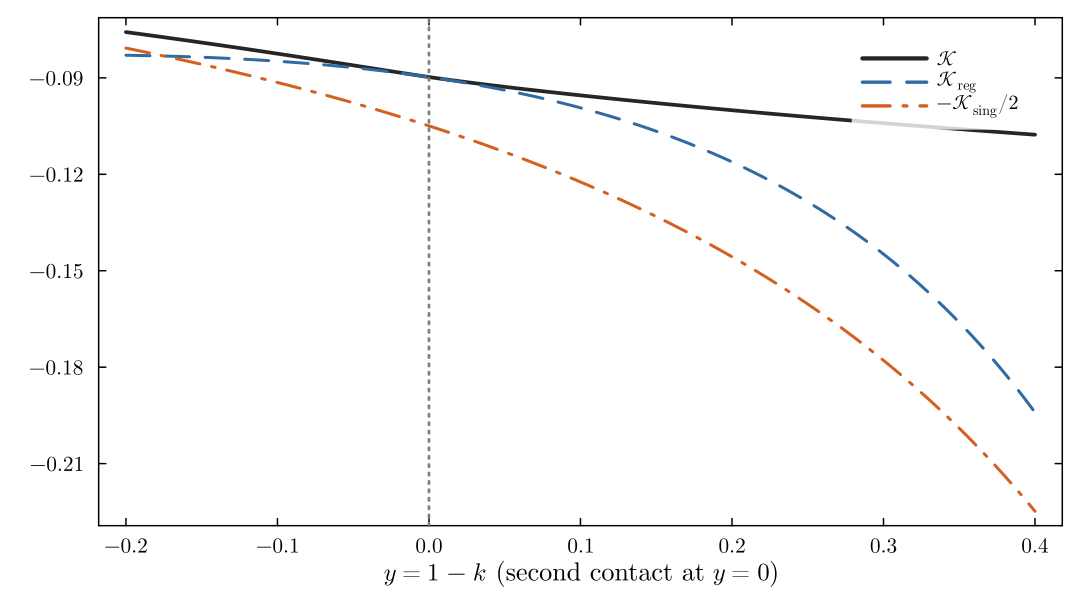

In [10]:
zofk(k, p) = p * (1 - 2k) + sqrt(p^2 * (1 - 2k)^2 + 1 - p^2)        # inverse of k(z)
ν = (α + 3) / 2
function parts(y; p = p, α = α)
    k = 1 - y
    g = geom(zofk(k, p), p)
    K = blocked_flux(zofk(k, p), p, α / 2; series_tol = 0, limb = :quadrature) / prefactor(g, α)
    Ks = -K_bartky(k, -g.x * y / k, g.c0, α) / (k^ν * sin(π * ν))
    Kr = y >= 0 ? K - y^ν * Ks : K - cos(π * ν) * abs(y)^ν * Ks
    return K, Kr, Ks
end
ys = range(-0.2, 0.4, length = 241)
P = parts.(ys)
p1 = plot(ys, getindex.(P, 1), lw = 2.5, color = COLORS.ink, label = L"\mathcal{K}",
          xlabel = L"$y = 1 - k$ (second contact at $y = 0$)", legend = :topright)
plot!(p1, ys, getindex.(P, 2), lw = 2, color = COLORS.series, ls = :dash, label = L"\mathcal{K}_\mathrm{reg}")
plot!(p1, ys, -0.5 .* getindex.(P, 3), lw = 2, color = COLORS.limb, ls = :dashdot, label = L"-\mathcal{K}_\mathrm{sing}/2")
vline!(p1, [0.0], color = :gray50, ls = :dot, label = "")

The Chebyshev coefficients of the three functions on $y \in [-0.2, 0.4]$: $\mathcal K$ converges
only algebraically (the $y^\nu$ singularity), its two parts geometrically, to $\sim 10^{-13}$ at
degree 18 even on this wide interval. (The package splits the limb into three shorter pieces
and reaches $10^{-15}$ at degree 14–18.)

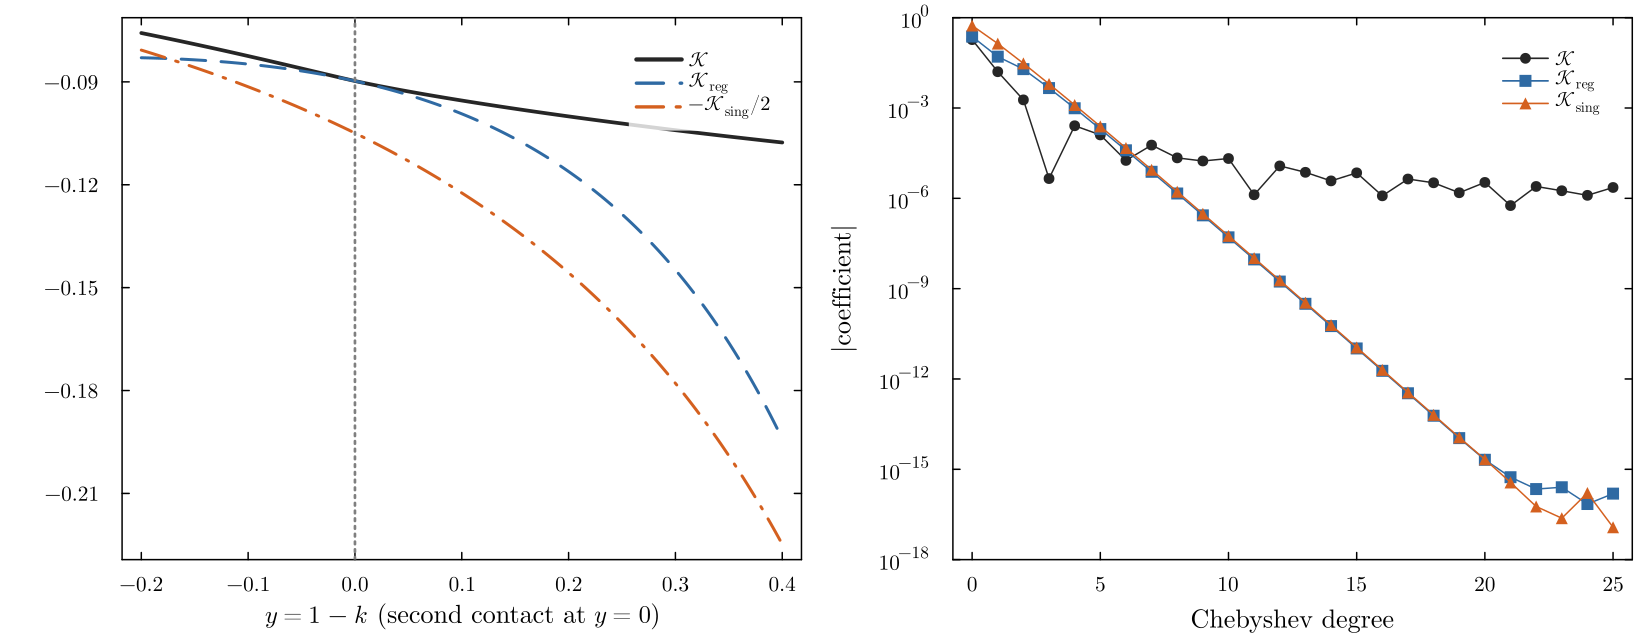

In [11]:
function cheb(f, a, b, n)
    θ = [π * (j + 0.5) / n for j in 0:n-1]
    v = [f((a + b) / 2 + (b - a) / 2 * cos(t)) for t in θ]
    [2 / n * sum(v[j] * cos(m * θ[j]) for j in 1:n) for m in 0:n-1]
end
n = 26
C = [cheb(y -> parts(y)[i], -0.2, 0.4, n) for i in 1:3]
p2 = plot(xlabel = "Chebyshev degree", ylabel = "|coefficient|", yscale = :log10, ylims = (1e-18, 1), legend = :topright)
for (i, (lab, col, mk)) in enumerate(((L"\mathcal{K}", COLORS.ink, :circle), (L"\mathcal{K}_\mathrm{reg}", COLORS.series, :rect),
                                      (L"\mathcal{K}_\mathrm{sing}", COLORS.limb, :utriangle)))
    plot!(p2, 0:n-1, max.(abs.(C[i]), 1e-18), color = col, marker = mk, ms = 4, msw = 0, lw = 1, label = lab)
end
plt = plot(p1, p2, layout = (1, 2), size = (1100, 430), left_margin = 6Plots.mm, bottom_margin = 6Plots.mm)
plt

In [12]:
table(["degree 18", "𝒦", "𝒦_reg", "𝒦_sing"], [("abs coefficient", sci(abs(C[1][19])), sci(abs(C[2][19])), sci(abs(C[3][19])))])

degree 18,𝒦,𝒦_reg,𝒦_sing
abs coefficient,3.3e-06,6.0e-14,6.4e-14


## 5. `BigFloat` for free

Because `K_bartky` is generic, an arbitrary-precision limb flux needs only a smaller step and a
longer tail. At $h = 0.1$ the error is about $10^{-39}$ (the change to $h = 0.08$ below), so the
value is shown to 38 digits.

In [13]:
Pb, Pb2 = setprecision(BigFloat, 200) do
    zb, pb, αb = big"0.97", big"0.1", big"0.6"
    g = geom(zb, pb)
    prefactor(g, αb) * K_bartky(g.y, g.x, g.c0, αb; h = big"0.1", tail = 1e-45),
    prefactor(g, αb) * K_bartky(g.y, g.x, g.c0, αb; h = big"0.08", tail = 1e-50)
end
table(["", ""], [("P_α(z = 0.97), h = 0.1", "`" * string(Pb)[1:40] * "…`"),
                 ("change with h = 0.08", sci(Float64(abs(Pb2 - Pb)))),
                 ("Float64 package value minus this", sci(Float64(blocked_flux(0.97, 0.1, 0.3; limb = :trapezoid) - Pb)))])

,
"P_α(z = 0.97), h = 0.1",0.01033828691671644878672370388991782805…
change with h = 0.08,1.3e-39
Float64 package value minus this,-4.8e-17


## 6. Cost

The package folds the exponent into the weights $w_n\cosh^{-(\alpha+3)}\beta_n$ once per light
curve, so a sample costs one square root and one division per node, shared by all exponents of
a law. The interpolants cost about 40 µs to build and then a few dozen nanoseconds per sample.
Per limb sample, power-2 law, $p = 0.1$:

In [14]:
law = Power2(0.6, 0.6)
zc = series_cut(p, law)
zl = collect(range(zc + 1e-9, 1 + p - 1e-9, length = 20_000))      # limb samples only
out = similar(zl)
rows = map([:trapezoid, :interpolate, :quadrature]) do lm
    o = Occultor(p, law; limb = lm, nlimb = length(zl))
    ("`limb = :$lm`", @sprintf("%.0f ns", 1e9 * @belapsed(evaluate!($out, $o, $zl)) / length(zl)))
end
g = geom(1.0, p)
push!(rows, ("the generic `K_bartky` above (`pow` and `cosh` at every node)",
             @sprintf("%.0f ns", 1e9 * @belapsed(K_bartky($(g.y), $(g.x), $(g.c0), $α)))))
table(["", "per sample"], rows)

,per sample
limb = :trapezoid,460 ns
limb = :interpolate,41 ns
limb = :quadrature,915 ns
the generic K_bartky above (pow and cosh at every node),2927 ns


## What you learned

- the limb integral is a complete integral; in Bartky's variable its integrand is analytic in
  a strip of fixed width $\pi/2$ for every modulus, so a trapezoid rule on fixed nodes converges
  like $\exp(-\pi^2/h)$ up to both contacts, once the poles' residue term is subtracted;
- inside the disk the same rule runs on a shifted contour;
- the singular part at second contact is the same integral at the complementary modulus, so
  $\mathcal K_{\rm reg}$ and $\mathcal K_{\rm sing}$ are smooth, and Chebyshev interpolants of
  modest degree reach $10^{-15}$;
- written generically, the rule gives arbitrary-precision references in a few lines.

See the paper, Sect. 6.4, Table D.6 and Fig. 2, for where this rule sits among the methods.